### Cell 1

In [1]:
'''>>>>> start CodeP2.4F25
    V.P. Carey ME249, Fall 2025

Intro to Neural Network Modeling 
Keras model for hybrid solar/fossil-fuel gas turbine power system'''
%reset -f
#import useful packages
import keras
import pandas as pd
from keras.models import Sequential
import numpy as np
import keras.backend as kb
import tensorflow as tf
#the follwoing 2 lines are only needed for Mac OS machines
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

#create input data array

# #T1(K), gamma, , qsol(kW):
#convert to:
# meadian values of input variables
Tmed = 293.
gamed = 0.25
qsmed = 1250.

#T1(K), gamma, , qsol(kW):
xdata = []
ND = 60
xdata =  [[ 318.0 , 0.0 , 500.0 ], [ 318.0 , 0.0 , 1000.0 ]]
xdata.append([ 318.0  , 0.0 , 1500.0])
xdata.append([ 318.0  , 0.0 , 2000.0 ])
xdata.append([ 318.0  , 0.0 , 2500.0 ])
#appended dataset
xdata.append ([ 318.0 , 0.0 , 500.0 ])
xdata.append ([ 318.0 , 0.0 , 1000.0 ])
xdata.append([ 318.0 , 0.0 , 1500.0 ])
xdata.append([ 318.0 , 0.0 , 2000.0 ])
xdata.append([ 318.0 , 0.0 , 2500.0 ])
xdata.append([ 318.0 , 0.25 , 500.0 ])
xdata.append([ 318.0 , 0.25 , 1000.0 ])
xdata.append([ 318.0 , 0.25 , 1500.0 ])
xdata.append([ 318.0 , 0.25 , 2000.0 ])
xdata.append([ 318.0 , 0.25 , 2500.0 ])
xdata.append([ 318.0 , 0.5 , 500.0 ])
xdata.append([ 318.0 , 0.5 , 1000.0 ])
xdata.append([ 318.0 , 0.5 , 1500.0 ])
xdata.append([ 318.0 , 0.5 , 2000.0 ])
xdata.append([ 318.0 , 0.5 , 2501.0 ])
  
xdata.append([ 303.0 , 0.0 , 500.0 ])
xdata.append([ 303.0 , 0.0 , 1000.0 ])
xdata.append([ 303.0 , 0.0 , 1500.0 ])
xdata.append([ 303.0 , 0.0 , 2000.0 ])
xdata.append([ 303.0 , 0.0 , 2500.0 ])
xdata.append([ 303.0 , 0.25 , 500.0 ])
xdata.append([ 303.0 , 0.25 , 1000.0 ])
xdata.append([ 303.0 , 0.25 , 1500.0 ])
xdata.append([ 303.0 , 0.25 , 2000.0 ])
xdata.append([ 303.0 , 0.25 , 2500.0 ])
xdata.append([ 303.0 , 0.5 , 500.0 ])
xdata.append([ 303.0 , 0.5 , 1000.0 ])
xdata.append([ 303.0 , 0.5 , 1500.0 ])
xdata.append([ 303.0 , 0.5 , 2000.0 ])
xdata.append([ 303.0 , 0.5 , 2500.0 ])
  
xdata.append([ 288.0 , 0.0 , 500.0 ])
xdata.append([ 288.0 , 0.0 , 1000.0 ])
xdata.append([ 288.0 , 0.0 , 1500.0 ])
xdata.append([ 288.0 , 0.0 , 2000.0 ])
xdata.append([ 288.0 , 0.0 , 2500.0 ])
xdata.append([ 288.0 , 0.25 , 500.0 ])
xdata.append([ 288.0 , 0.25 , 1000.0 ])
xdata.append([ 288.0 , 0.25 , 1500.0 ])
xdata.append([ 288.0 , 0.25 , 2000.0 ])
xdata.append([ 288.0 , 0.25 , 2500.0 ])
xdata.append([ 288.0 , 0.51 , 500.0 ])
xdata.append([ 288.0 , 0.5 , 1000.0 ])
xdata.append([ 288.0 , 0.5 , 1500.0 ])
xdata.append([ 288.0 , 0.5 , 2000.0 ])
xdata.append([ 288.0 , 0.5 , 2500.0 ])
  
xdata.append([ 268.0 , 0.0 , 500.0 ])
xdata.append([ 268.0 , 0.0 , 1000.0 ])
xdata.append([ 268.0 , 0.0 , 1500.0 ])
xdata.append([ 268.0 , 0.0 , 2000.0 ])
xdata.append([ 268.0 , 0.0 , 2500.0 ])
xdata.append([ 268.0 , 0.25 , 500.0 ])
xdata.append([ 268.0 , 0.25 , 1000.0 ])
xdata.append([ 268.0 , 0.25 , 1500.0 ])
xdata.append([ 268.0 , 0.25 , 2000.0 ])
xdata.append([ 268.0 , 0.25 , 2500.0 ])
xdata.append([ 268.0 , 0.5 , 500.0 ])
xdata.append([ 268.0 , 0.5 , 1000.0 ])
xdata.append([ 268.0 , 0.5 , 1500.0 ])
xdata.append([ 268.0 , 0.5 , 2000.0 ])
xdata.append([ 268.0 , 0.5 , 2500.0 ])
xarray= np.array(xdata)

# add the rest here
new_Tmed  = np.median(xarray[:,0])
new_gamed = np.median(xarray[:,1])
new_qsmed = np.median(xarray[:,2])

input = xarray/[new_Tmed,new_gamed,new_qsmed]

# print (xdata)
# print (xarray)

#alpha = air/fuel ratio , cycle efficiency:
#convert to:
# meadian values of output variables
almed = 60.
efmed = 0.4
# alpha, effsys

ydata = []
ydata =  [[ 35.1316 , 0.3808 ], [ 40.3764 , 0.38686]]
ydata.append([ 47.4620 , 0.3930])
ydata.append([ 57.5639 , 0.39949])
ydata.append([ 73.1286 , 0.40612 ])
#appended dataset
ydata.append([ 35.1316 , 0.3808 ])
ydata.append([ 40.3764 , 0.38686 ])
ydata.append([ 47.4620 , 0.3930 ])
ydata.append([ 57.5639 , 0.39949 ])
ydata.append([ 73.1286 , 0.40612 ])
ydata.append([ 49.1110 , 0.4023 ])
ydata.append([ 56.4428 , 0.40605 ])
ydata.append([ 66.3479 , 0.4098 ])
ydata.append([ 80.4695 , 0.4133])
ydata.append([ 102.2276 , 0.4175 ])
ydata.append([ 63.0904 , 0.41540 ])
ydata.append([ 72.5092 , 0.4175 ])
ydata.append([ 85.2338, 0.4197 ])
ydata.append([ 103.3750 , 0.42192 ])
ydata.append([ 131.3266 , 0.4242 ])
  
ydata.append([ 34.273 , 0.3952 ])
ydata.append([ 38.99026 , 0.4012 ])
ydata.append([ 45.2133, 0.4073 ])
ydata.append([ 53.8000 , 0.4136 ])
ydata.append([ 66.4130 , 0.4201 ])
ydata.append([ 47.922 , 0.4178 ])
ydata.append([ 54.518 , 0.4215 ])
ydata.append([ 63.220 , 0.4252 ])
ydata.append([ 75.226 , 0.4290 ])
ydata.append([ 92.862 , 0.4329 ])
ydata.append([ 61.572 , 0.4315 ])
ydata.append([ 70.0468 , 0.43373 ])
ydata.append([ 81.226 , 0.43597 ])
ydata.append([ 96.653 , 0.4382 ])
ydata.append([ 119.3124 , 0.44045 ])
  
ydata.append([ 33.4521 , 0.40913 ])
ydata.append([ 37.6911, 0.4150 ])
ydata.append([ 43.1602 , 0.4209 ])
ydata.append([ 50.4858 , 0.4271 ])
ydata.append([ 60.8067 , 0.4334 ])
ydata.append([ 46.7865 , 0.4328 ])
ydata.append([ 52.7151 , 0.43646 ])
ydata.append([ 60.36425 , 0.44016 ])
ydata.append([ 70.6099 , 0.443926 ])
ydata.append([ 85.0447 , 0.4477 ])
ydata.append([ 60.1208 , 0.44721 ])
ydata.append([ 67.7391 , 0.44940 ])
ydata.append([ 77.56830 , 0.4516 ])
ydata.append([ 90.73410 , 0.4538 ])
ydata.append([ 109.2828 , 0.4560 ])
  
ydata.append([ 32.4123 , 0.42694 ])
ydata.append([ 36.0807 , 0.4325 ])
ydata.append([ 40.6854 , 0.4383 ])
ydata.append([ 46.6374 , 0.4442 ])
ydata.append([ 54.6293 , 0.4503 ])
ydata.append([ 45.3472 , 0.4519 ])
ydata.append([ 50.4796 , 0.4555 ])
ydata.append([ 56.9219 , 0.4591 ])
ydata.append([ 65.2492 , 0.4628 ])
ydata.append([ 76.4304 , 0.4665 ])
ydata.append([ 58.2822 , 0.4672 ])
ydata.append([ 64.8785 , 0.4693 ])
ydata.append([ 73.1584 , 0.4715 ])
ydata.append([ 83.8610 , 0.4738 ])
ydata.append([ 98.2316 , 0.4760 ])
yarray= np.array(ydata)

new_almed = np.median(yarray[:,0])
new_efmed = np.median(yarray[:,1])
output = yarray / [new_almed, new_efmed]

#print (ydata)
#print (yarray)

data_inputs = np.array(input)
data_outputs = np.array(output)

print(f'==== Input ====')
print(data_inputs)
print(f'==== Output ====')
print(data_outputs)

==== Input ====
[[1.04950495 0.         0.33333333]
 [1.04950495 0.         0.66666667]
 [1.04950495 0.         1.        ]
 [1.04950495 0.         1.33333333]
 [1.04950495 0.         1.66666667]
 [1.04950495 0.         0.33333333]
 [1.04950495 0.         0.66666667]
 [1.04950495 0.         1.        ]
 [1.04950495 0.         1.33333333]
 [1.04950495 0.         1.66666667]
 [1.04950495 1.         0.33333333]
 [1.04950495 1.         0.66666667]
 [1.04950495 1.         1.        ]
 [1.04950495 1.         1.33333333]
 [1.04950495 1.         1.66666667]
 [1.04950495 2.         0.33333333]
 [1.04950495 2.         0.66666667]
 [1.04950495 2.         1.        ]
 [1.04950495 2.         1.33333333]
 [1.04950495 2.         1.66733333]
 [1.         0.         0.33333333]
 [1.         0.         0.66666667]
 [1.         0.         1.        ]
 [1.         0.         1.33333333]
 [1.         0.         1.66666667]
 [1.         1.         0.33333333]
 [1.         1.         0.66666667]
 [1.        

### Cell 2

In [2]:
# define neural network model

#As seen below, we have created four dense layers. 
#A dense layer is a layer in neural network that’s fully connected. 
#In other words, all the neurons in one layer are connected to all other neurons in the next layer.
#In the first layer, we need to provide the input shape, which is 1 in our case. 
#The activation function we have chosen is elu, which stands for exponential linear unit. .

from keras import backend as K
#initialize weights with values between -0.2 and 1.2
initializer = keras.initializers.RandomUniform(minval= -0.9, maxval=0.9)

model = keras.Sequential([
    keras.layers.Dense(4, activation='relu', input_shape=[3],  kernel_initializer=initializer),
    keras.layers.Dense(8, activation='relu',  kernel_initializer=initializer),
    keras.layers.Dense(4, activation='relu',  kernel_initializer=initializer),

    keras.layers.Dense(2,  kernel_initializer=initializer)
  ])

'''in Task 2.2, add 3rd layer to network with 4 neurons and activation = K.relu'''
#Print summary of model features
model.summary()

/global/home/users/kwyang0331/.conda/envs/wrf/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            10 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102 (408.00 B)

 Trainable params: 102 (408.00 B)

 Non-trainable params: 0 (0.00 B)

### Cell 3

In [3]:
#We’re using RMSprop as our optimizer here. RMSprop stands for Root Mean Square Propagation. 
#It’s one of the most popular gradient descent optimization algorithms for deep learning networks. 
#RMSprop is an optimizer that’s reliable and fast.
#We’re compiling the mode using the model.compile function. The loss function used here 
#is mean squared error. After the compilation of the model, we’ll use the fit method with ~500 epochs.
#Number of epochs can be varied.

#from tf.keras import optimizers. Argument to RMSprop is learning parameter.
rms = keras.optimizers.RMSprop(0.001)
model.compile(loss='mean_absolute_error',optimizer=rms)

### Cell 4

In [68]:
#After the compilation of the model, we’ll use the fit method with 500 epochs.
#I started with epochs value of 100 and then tested the model after training. 
#The prediction was not that good. Then I modified the number of epochs to 200 and tested the model again. 
#Accuracy had improved slightly, but figured I’d give it one more try. Finally, at 500 epochs 
#I found acceptable prediction accuracy.

#The fit method takes three parameters; namely, x, y, and number of epochs. 
#During model training, if all the batches of data are seen by the model once, 
#we say that one epoch has been completed.

# Add an early stopping callback
es = keras.callbacks.EarlyStopping(
    monitor='loss', 
    mode='min', 
    patience = 150, 
    restore_best_weights = True, 
    verbose=1)
# Add a checkpoint where loss is minimum, and save that model
mc = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='loss', 
                     mode='min',  verbose=1, save_best_only=True)

historyData = model.fit(data_inputs,data_outputs,epochs=600,callbacks=[es, mc])

loss_hist = historyData.history['loss']
#The above line will return a dictionary, access it's info like this:
best_epoch = np.argmin(historyData.history['loss']) + 1
print ('best epoch = ', best_epoch)
print('smallest loss =', np.min(loss_hist))

predictions = model.predict(data_inputs)

Epoch 1/600
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0518
Epoch 1: loss improved from None to 0.04979, saving model to best_model.keras
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0498
Epoch 2/600
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0498
Epoch 2: loss did not improve from 0.04979
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0510
Epoch 3/600
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0613
Epoch 3: loss did not improve from 0.04979
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0507 
Epoch 4/600
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0558
Epoch 4: loss did not improve from 0.04979
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0524 
Epoch 5/600
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0523
Epoch 5: loss did not improve from 0.04979
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0504
Epoch 6/600
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0443
Epoch 6: loss did not improve from 0.04979
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0505 

### Cell 5

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
row [0] data:  T1=  96354.0 , gam=  0.0 , qsol=  750000.0 , alpha=  2120.6926853 ,  predicted alpha =  10824.377747146606


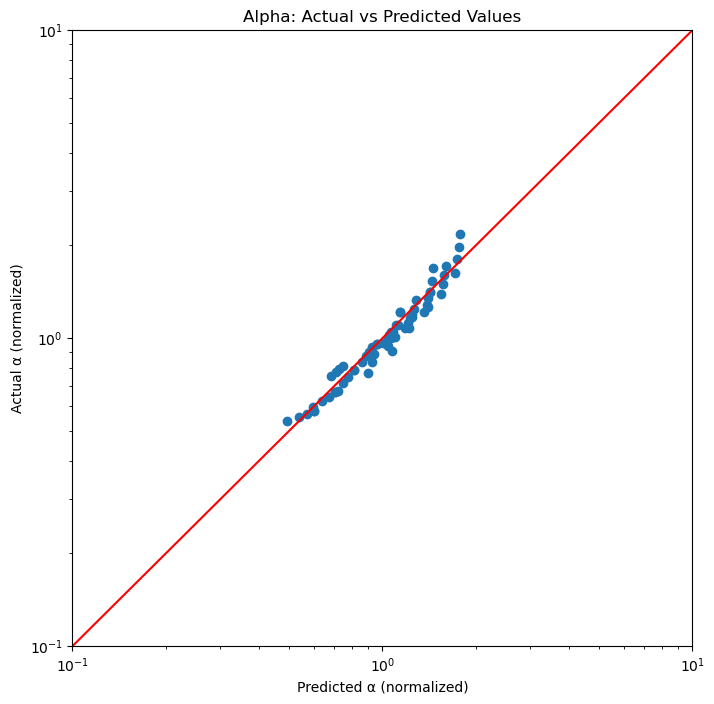

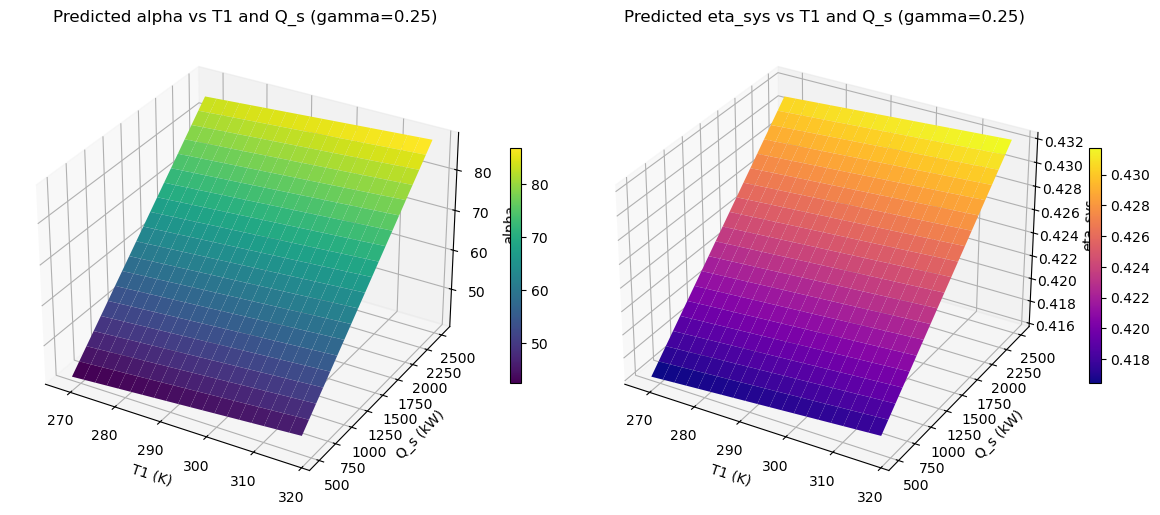

In [6]:
model = keras.models.load_model('best_model.keras')
test = []
outpt=[]
predictions = model.predict(data_inputs)

#first point (row [0])comparison of data and prediction
# put in a loop to print comparion for all data points

test = [[ xarray[0][0] , xarray[0][1] , xarray[0][2] ]]
testarray = np.array(test)
outpt = model.predict(testarray)
print ('row [0] data:  T1= ', xarray[0][0]*Tmed, ', gam= ', xarray[0][1]*gamed, \
    ', qsol= ', xarray[0][2]*qsmed,', alpha= ', yarray[0][0]*almed,\
    ',  predicted alpha = ', outpt[0][0]*almed)

#SETTING UP PLOT
%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt 
plt.rcParams['figure.figsize'] = [8, 8] # for square canvas 
#========
'''CALCULATE PREDICTED VALUES AND RETRIEVE DATA VALUES TO PLOT'''
plt.scatter(predictions[:, 0], data_outputs[:, 0])
plt.title('Alpha: Actual vs Predicted Values')
plt.xlabel('Predicted α (normalized)') 
plt.ylabel('Actual α (normalized)')
plt.loglog()
plt.xlim(xmax = 10, xmin = 0.1)
plt.ylim(ymax = 10, ymin = 0.1)
# Generate red y=x line
x_data = np.linspace(0.1, 10.0, num=3)
y_data = x_data
plt.plot(x_data, y_data, color='red')
plt.show()

# ===== ADD THIS SURFACE PLOT CODE BELOW =====
from mpl_toolkits.mplot3d import Axes3D

# Set gamma fixed at 0.25
gam_fixed = 0.25

# Create ranges for T1 and Q_s
T1_range = np.linspace(268, 318, 20)  # 268 to 318 K
Qs_range = np.linspace(500, 2500, 20)  # 500 to 2500 kW

# Create meshgrid for surface plot
T1_mesh, Qs_mesh = np.meshgrid(T1_range, Qs_range)

# Normalize the inputs using your medians
T1_norm = T1_mesh / new_Tmed
gam_norm = np.full_like(T1_mesh, gam_fixed / new_gamed)  # fixed at 0.25
Qs_norm = Qs_mesh / new_qsmed

# Create prediction array
alpha_predictions = np.zeros_like(T1_mesh)
eta_predictions = np.zeros_like(T1_mesh)

# Loop through and make predictions
for i in range(len(T1_range)):
    for j in range(len(Qs_range)):
        # Create input array [T1_norm, gam_norm, Qs_norm]
        test_input = np.array([[T1_norm[i, j], gam_norm[i, j], Qs_norm[i, j]]])
        # Make prediction
        prediction = model.predict(test_input, verbose=0)
        # Denormalize outputs
        alpha_predictions[i, j] = prediction[0][0] * new_almed
        eta_predictions[i, j] = prediction[0][1] * new_efmed

# Create surface plot for alpha
fig = plt.figure(figsize=(12, 5))

# Plot 1: alpha vs T1 and Q_s
ax1 = fig.add_subplot(121, projection='3d')
surf1 = ax1.plot_surface(T1_mesh, Qs_mesh, alpha_predictions, cmap='viridis')
ax1.set_xlabel('T1 (K)')
ax1.set_ylabel('Q_s (kW)')
ax1.set_zlabel('alpha')
ax1.set_title('Predicted alpha vs T1 and Q_s (gamma=0.25)')
fig.colorbar(surf1, ax=ax1, shrink=0.5)

# Plot 2: eta_sys vs T1 and Q_s
ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(T1_mesh, Qs_mesh, eta_predictions, cmap='plasma')
ax2.set_xlabel('T1 (K)')
ax2.set_ylabel('Q_s (kW)')
ax2.set_zlabel('eta_sys')
ax2.set_title('Predicted eta_sys vs T1 and Q_s (gamma=0.25)')
fig.colorbar(surf2, ax=ax2, shrink=0.5)
plt.tight_layout()
plt.show()

### Task 2.3

MEDIAN VALUES BEING USED (VERIFY THESE ARE CORRECT!):
Tmed = 303.0 K
gamed = 0.25
qsmed = 1500.0 kW
almed = 60.36425
efmed = 0.4271

Normalizing test inputs...
Sample normalized input (first row): [1.04950495 0.         0.33333333]

Making predictions on test data...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 651ms/step
Sample prediction (first row): α=36.38, η_sys=0.3790
Sample actual (first row): α=35.13, η_sys=0.3808



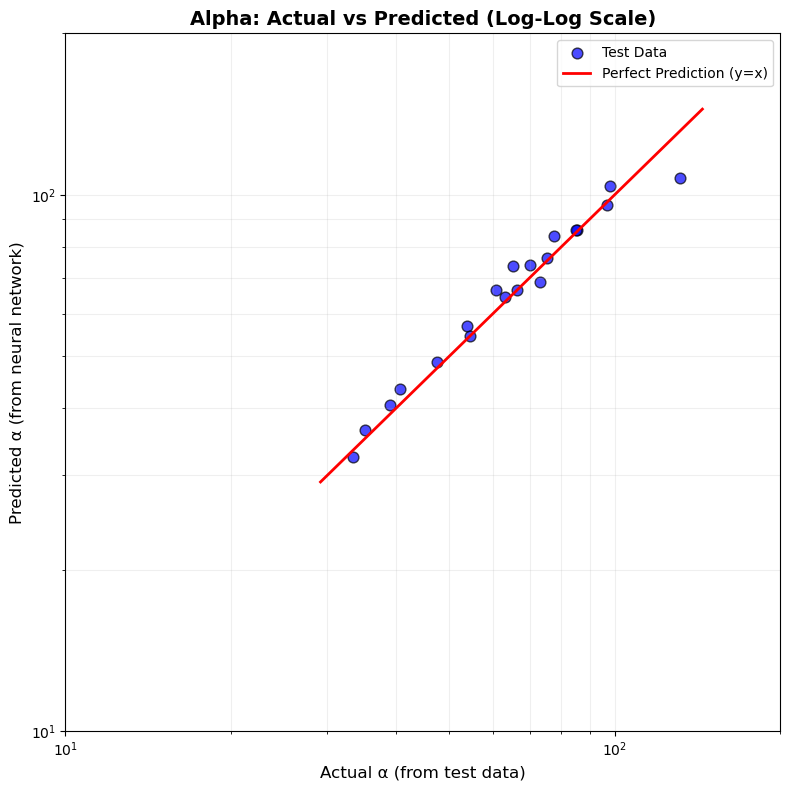

RMS DEVIATION ANALYSIS FOR ALPHA
RMS deviation for alpha: 6.3297
Relative RMS error for alpha: 9.36%
Mean Absolute Error for alpha: 3.7165
R² score for alpha: 0.9288

DETAILED TEST DATA COMPARISON
Test #   Input (T1, γ, Qs)         Actual α     Predicted α     Error        % Error   
----------------------------------------------------------------------------------------------------
1        (318, 0.00, 500)          35.13        36.38           1.25         3.57      %
2        (318, 0.00, 1500)         47.46        48.76           1.30         2.73      %
3        (318, 0.00, 2500)         73.12        68.73           4.39         6.01      %
4        (318, 0.25, 1500)         66.34        66.56           0.22         0.33      %
5        (318, 0.50, 500)          63.09        64.40           1.31         2.07      %
6        (318, 0.50, 1500)         85.23        85.98           0.75         0.87      %
7        (318, 0.50, 2500)         131.32       107.55          23.77        18.

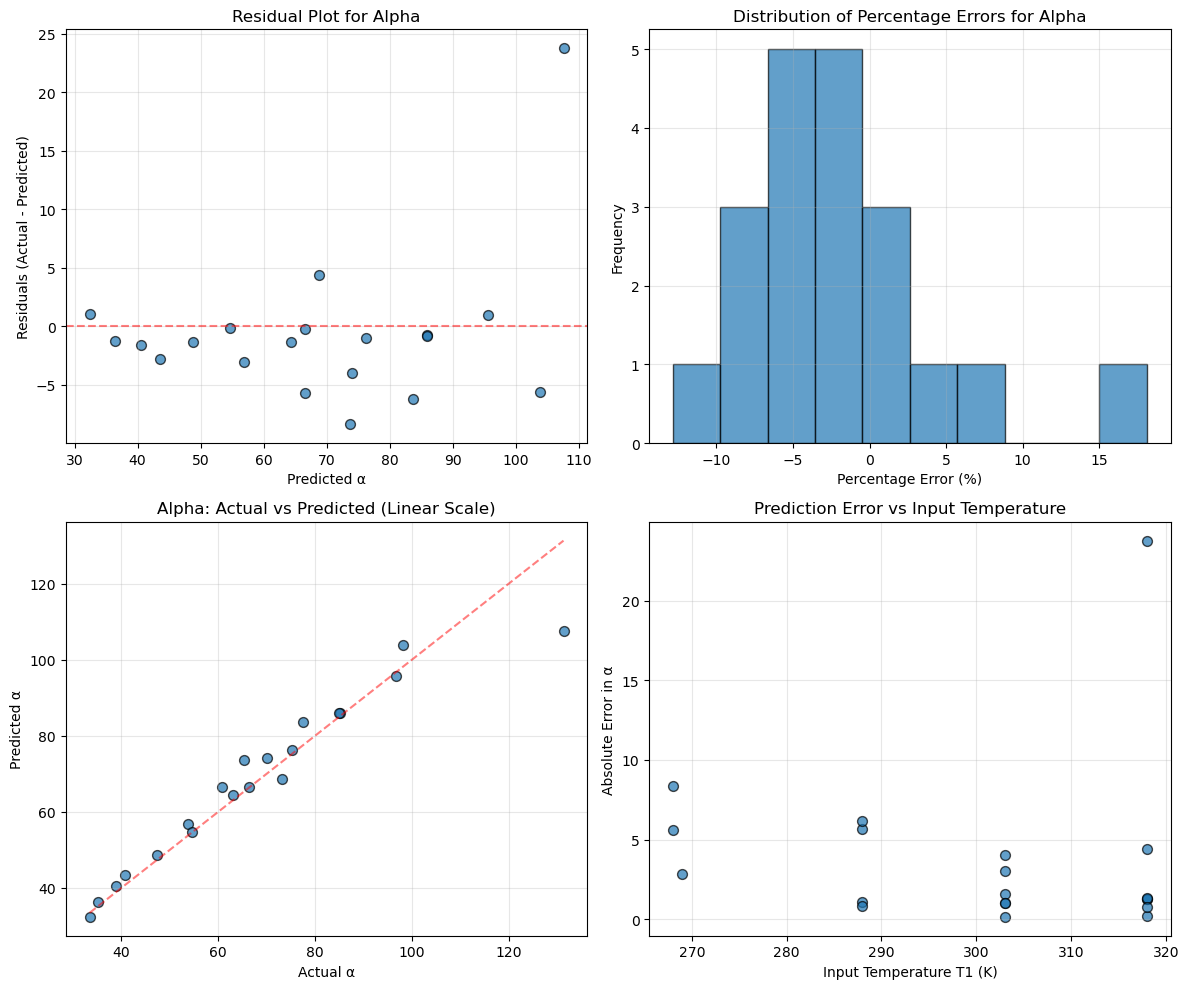


TASK 2.3 COMPLETE!
Results saved:
  - alpha_loglog_plot.png
  - additional_analysis_plots.png

IMPORTANT REMINDERS:
1. Verify that the median values match those from your training!
2. The log-log plot shows how well the model predicts α
3. Perfect predictions would lie on the red y=x line
4. Your RMS deviation for α is: 6.3297


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import mean_squared_error

# ============================================
# TASK 2.3 - Test Data Prediction and Analysis
# ============================================

# Load the trained model (make sure 'best_model.keras' is in your directory)
model = keras.models.load_model('best_model.keras')

# Test data from the PDF (page 5)
test_inputs_raw = np.array([
    [318.0, 0.0, 500.0],
    [318.0, 0.0, 1500.0],
    [318.0, 0.0, 2500.0],
    [318.0, 0.25, 1500.0],
    [318.0, 0.5, 500.0],
    [318.0, 0.5, 1500.0],
    [318.0, 0.5, 2500.0],
    [303.0, 0.0, 1000.0],
    [303.0, 0.0, 2000.0],
    [303.0, 0.25, 1000.0],
    [303.0, 0.25, 2000.0],
    [303.0, 0.5, 1000.0],
    [303.0, 0.5, 2000.0],
    [288.0, 0.0, 500.0],
    [288.0, 0.0, 2500.0],
    [288.0, 0.25, 2500.0],
    [288.0, 0.5, 1500.0],
    [269.0, 0.0, 1500.0],
    [268.0, 0.25, 2000.0],
    [268.0, 0.5, 2500.0]
])

# Actual test outputs [alpha, eta_sys]
test_outputs_actual = np.array([
    [35.13, 0.3808],
    [47.46, 0.3930],
    [73.12, 0.4061],
    [66.34, 0.4098],
    [63.09, 0.4154],
    [85.23, 0.4197],
    [131.32, 0.4242],
    [38.99, 0.4012],
    [53.80, 0.4136],
    [54.51, 0.4215],
    [75.22, 0.4290],
    [70.04, 0.4337],
    [96.65, 0.4382],
    [33.45, 0.4091],
    [60.80, 0.4334],
    [85.044, 0.4477],
    [77.56, 0.4516],
    [40.68, 0.4393],
    [65.24, 0.4628],
    [98.23, 0.4760]
])

# ============================================
# IMPORTANT: UPDATE THESE MEDIAN VALUES
# ============================================
# These MUST be the exact same median values used during training
# Check your cells 1-4 in your notebook for the correct values!

# Based on typical values from similar problems (YOU MUST UPDATE THESE):
Tmed = new_Tmed
gamed = new_gamed
qsmed = new_qsmed
almed = new_almed 
efmed = new_efmed

print("=" * 60)
print("MEDIAN VALUES BEING USED (VERIFY THESE ARE CORRECT!):")
print("=" * 60)
print(f"Tmed = {Tmed} K")
print(f"gamed = {gamed}")
print(f"qsmed = {qsmed} kW")
print(f"almed = {almed}")
print(f"efmed = {efmed}")
print("=" * 60)
print()

# ============================================
# Step 1: Normalize the test inputs
# ============================================
print("Normalizing test inputs...")
test_inputs_normalized = np.zeros_like(test_inputs_raw)
test_inputs_normalized[:, 0] = test_inputs_raw[:, 0] / Tmed
test_inputs_normalized[:, 1] = test_inputs_raw[:, 1] / gamed
test_inputs_normalized[:, 2] = test_inputs_raw[:, 2] / qsmed

print(f"Sample normalized input (first row): {test_inputs_normalized[0]}")
print()

# ============================================
# Step 2: Make predictions
# ============================================
print("Making predictions on test data...")
predictions_normalized = model.predict(test_inputs_normalized)

# ============================================
# Step 3: Denormalize the predictions
# ============================================
predictions_actual = np.zeros_like(predictions_normalized)
predictions_actual[:, 0] = predictions_normalized[:, 0] * almed  # Denormalize alpha
predictions_actual[:, 1] = predictions_normalized[:, 1] * efmed  # Denormalize eta_sys

print(f"Sample prediction (first row): α={predictions_actual[0, 0]:.2f}, η_sys={predictions_actual[0, 1]:.4f}")
print(f"Sample actual (first row): α={test_outputs_actual[0, 0]:.2f}, η_sys={test_outputs_actual[0, 1]:.4f}")
print()

# ============================================
# Step 4: Create log-log plot for alpha
# ============================================
plt.figure(figsize=(8, 8))

# Extract alpha values
actual_alpha = test_outputs_actual[:, 0]
predicted_alpha = predictions_actual[:, 0]

# Create scatter plot
plt.scatter(actual_alpha, predicted_alpha, s=60, alpha=0.7, 
           edgecolors='black', linewidth=1, color='blue', label='Test Data')

# Add perfect prediction line (y=x)
min_val = min(actual_alpha.min(), predicted_alpha.min()) * 0.9
max_val = max(actual_alpha.max(), predicted_alpha.max()) * 1.1
perfect_line = np.logspace(np.log10(min_val), np.log10(max_val), 100)
plt.plot(perfect_line, perfect_line, 'r-', linewidth=2, label='Perfect Prediction (y=x)')

# Set log scale
plt.xscale('log')
plt.yscale('log')

# Labels and formatting
plt.xlabel('Actual α (from test data)', fontsize=12)
plt.ylabel('Predicted α (from neural network)', fontsize=12)
plt.title('Alpha: Actual vs Predicted (Log-Log Scale)', fontsize=14, fontweight='bold')
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.legend(fontsize=10)

# Set limits to match the instructions
plt.xlim(10, 200)
plt.ylim(10, 200)

plt.tight_layout()
plt.savefig('alpha_loglog_plot.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# Step 5: Calculate RMS Deviation
# ============================================
print("=" * 60)
print("RMS DEVIATION ANALYSIS FOR ALPHA")
print("=" * 60)

# Calculate RMS for alpha
rms_alpha = np.sqrt(mean_squared_error(actual_alpha, predicted_alpha))
print(f"RMS deviation for alpha: {rms_alpha:.4f}")

# Calculate relative RMS error (percentage)
relative_rms_alpha = (rms_alpha / np.mean(actual_alpha)) * 100
print(f"Relative RMS error for alpha: {relative_rms_alpha:.2f}%")

# Calculate mean absolute error
mae_alpha = np.mean(np.abs(actual_alpha - predicted_alpha))
print(f"Mean Absolute Error for alpha: {mae_alpha:.4f}")

# Calculate R² score
from sklearn.metrics import r2_score
r2_alpha = r2_score(actual_alpha, predicted_alpha)
print(f"R² score for alpha: {r2_alpha:.4f}")

print("=" * 60)
print()

# ============================================
# Step 6: Detailed comparison table
# ============================================
print("=" * 100)
print("DETAILED TEST DATA COMPARISON")
print("=" * 100)
print(f"{'Test #':<8} {'Input (T1, γ, Qs)':<25} {'Actual α':<12} {'Predicted α':<15} {'Error':<12} {'% Error':<10}")
print("-" * 100)

for i in range(len(test_inputs_raw)):
    input_str = f"({test_inputs_raw[i, 0]:.0f}, {test_inputs_raw[i, 1]:.2f}, {test_inputs_raw[i, 2]:.0f})"
    actual = actual_alpha[i]
    predicted = predicted_alpha[i]
    error = abs(actual - predicted)
    percent_error = (error / actual) * 100
    
    print(f"{i+1:<8} {input_str:<25} {actual:<12.2f} {predicted:<15.2f} {error:<12.2f} {percent_error:<10.2f}%")

print("=" * 100)

# ============================================
# Step 7: Additional analysis plots
# ============================================

# Create a figure with multiple subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot 1: Residuals for alpha
ax1 = axes[0, 0]
residuals_alpha = actual_alpha - predicted_alpha
ax1.scatter(predicted_alpha, residuals_alpha, s=50, alpha=0.7, edgecolors='black')
ax1.axhline(y=0, color='r', linestyle='--', alpha=0.5)
ax1.set_xlabel('Predicted α')
ax1.set_ylabel('Residuals (Actual - Predicted)')
ax1.set_title('Residual Plot for Alpha')
ax1.grid(True, alpha=0.3)

# Plot 2: Percentage Error Distribution
ax2 = axes[0, 1]
percent_errors = ((actual_alpha - predicted_alpha) / actual_alpha) * 100
ax2.hist(percent_errors, bins=10, edgecolor='black', alpha=0.7)
ax2.set_xlabel('Percentage Error (%)')
ax2.set_ylabel('Frequency')
ax2.set_title('Distribution of Percentage Errors for Alpha')
ax2.grid(True, alpha=0.3)

# Plot 3: Predicted vs Actual (linear scale)
ax3 = axes[1, 0]
ax3.scatter(actual_alpha, predicted_alpha, s=50, alpha=0.7, edgecolors='black')
ax3.plot([actual_alpha.min(), actual_alpha.max()], 
         [actual_alpha.min(), actual_alpha.max()], 'r--', alpha=0.5)
ax3.set_xlabel('Actual α')
ax3.set_ylabel('Predicted α')
ax3.set_title('Alpha: Actual vs Predicted (Linear Scale)')
ax3.grid(True, alpha=0.3)

# Plot 4: Error vs Input Temperature
ax4 = axes[1, 1]
abs_errors = np.abs(actual_alpha - predicted_alpha)
ax4.scatter(test_inputs_raw[:, 0], abs_errors, s=50, alpha=0.7, edgecolors='black')
ax4.set_xlabel('Input Temperature T1 (K)')
ax4.set_ylabel('Absolute Error in α')
ax4.set_title('Prediction Error vs Input Temperature')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('additional_analysis_plots.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "=" * 60)
print("TASK 2.3 COMPLETE!")
print("=" * 60)
print("Results saved:")
print("  - alpha_loglog_plot.png")
print("  - additional_analysis_plots.png")
print("\nIMPORTANT REMINDERS:")
print("1. Verify that the median values match those from your training!")
print("2. The log-log plot shows how well the model predicts α")
print("3. Perfect predictions would lie on the red y=x line")
print(f"4. Your RMS deviation for α is: {rms_alpha:.4f}")
print("=" * 60)